In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración gráfica
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Carga de datos
df = pd.read_csv('MUNDAKA.csv', sep=';', encoding='latin1')

# 2. Conversión de fechas y ordenación cronológica
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values('Date').reset_index(drop=True)

# 3. Resumen estructural
print("--- DATAFRAME INFO ---")
print(df.info())
print("\n--- VALORES NULOS POR COLUMNA ---")
print(df.isnull().sum())
print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

--- DATAFRAME INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           306 non-null    datetime64[us]
 1   NO (µg/m3)     302 non-null    float64       
 2   NOX (µg/m3)    302 non-null    float64       
 3   NO2 (µg/m3)    302 non-null    float64       
 4   O3 (µg/m3)     304 non-null    float64       
 5   O3 8h (µg/m3)  211 non-null    float64       
 6   PM10 (µg/m3)   257 non-null    float64       
 7   PM2,5 (µg/m3)  304 non-null    float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 19.3 KB
None

--- VALORES NULOS POR COLUMNA ---
Date              0
NO (µg/m3)        4
NOX (µg/m3)       4
NO2 (µg/m3)       4
O3 (µg/m3)        2
O3 8h (µg/m3)    95
PM10 (µg/m3)     49
PM2,5 (µg/m3)     2
dtype: int64

--- ESTADÍSTICAS DESCRIPTIVAS ---


,Date,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),O3 8h (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)"
count,306,302.000000,302.000000,302.000000,304.000000,211.000000,257.000000,304.000000
mean,2026-06-02 12:00:00,0.450331,3.715232,3.043046,71.447368,73.706161,11.875486,5.720395
min,2026-01-01 00:00:00,0.000000,1.000000,0.000000,33.000000,36.000000,4.000000,1.000000
25%,2026-03-18 06:00:00,0.000000,2.000000,2.000000,61.750000,65.000000,8.000000,3.000000
50%,2026-06-02 12:00:00,0.000000,3.000000,3.000000,72.000000,74.000000,11.000000,5.000000
75%,2026-08-17 18:00:00,1.000000,5.000000,4.000000,82.000000,82.500000,15.000000,8.000000
max,2026-11-02 00:00:00,3.000000,11.000000,8.000000,116.000000,104.000000,35.000000,20.000000
std,NaN,0.654032,1.732540,1.347374,13.909319,12.482708,5.175821,3.455150


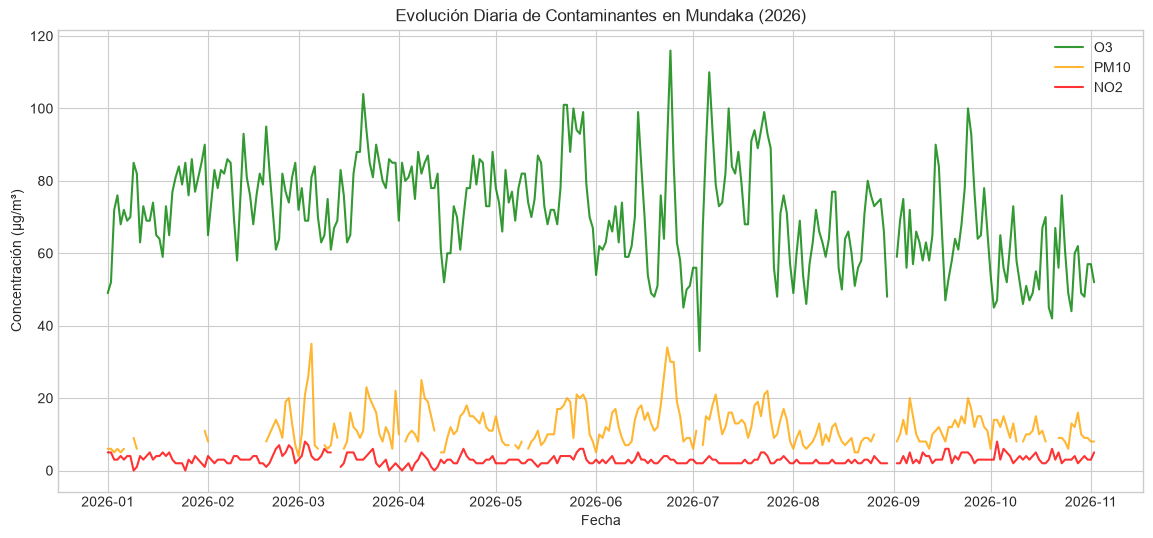

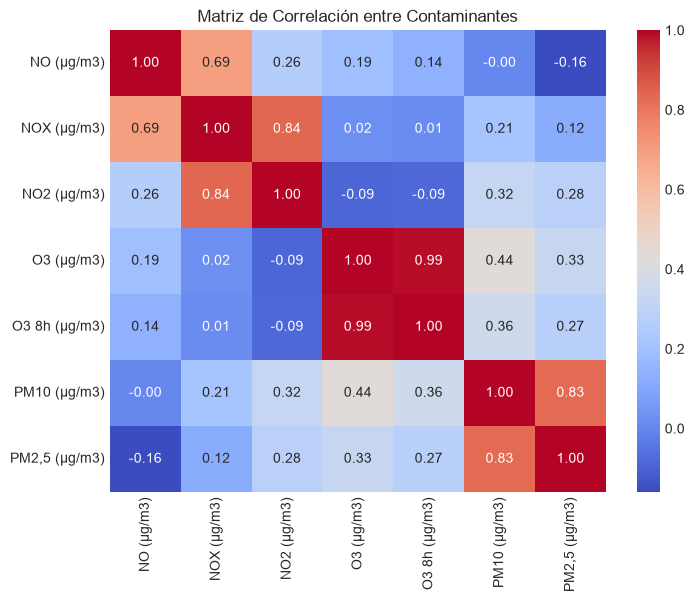

In [2]:
# 1. Evolución temporal de contaminantes clave
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['O3 (µg/m3)'], label='O3', color='green', alpha=0.8)
plt.plot(df['Date'], df['PM10 (µg/m3)'], label='PM10', color='orange', alpha=0.8)
plt.plot(df['Date'], df['NO2 (µg/m3)'], label='NO2', color='red', alpha=0.8)
plt.title('Evolución Diaria de Contaminantes en Mundaka (2026)')
plt.xlabel('Fecha')
plt.ylabel('Concentración (µg/m³)')
plt.legend()
plt.show()

# 2. Matriz de Correlación
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación entre Contaminantes')
plt.show()

In [3]:
# 1. Creación de variables temporales (Feature Engineering)
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['DayOfYear'] = df['Date'].dt.dayofyear

# 2. Eliminación de columna con exceso de nulos (>30%) si procede
if 'O3 8h (µg/m3)' in df.columns:
    df.drop(columns=['O3 8h (µg/m3)'], inplace=True)

# 3. Definición de variables predictoras (X) y objetivo opcional (y)
feature_cols = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)', 'Month', 'DayOfWeek']
X = df[feature_cols]

print("Características seleccionadas para entrenamiento:")
print(X.head())

Características seleccionadas para entrenamiento:
   NO (µg/m3)  NOX (µg/m3)  NO2 (µg/m3)  O3 (µg/m3)  PM2,5 (µg/m3)  Month  \
0         2.0          8.0          5.0        49.0            8.0      1   
1         2.0          9.0          5.0        52.0            5.0      1   
2         2.0          6.0          3.0        72.0            2.0      1   
3         2.0          6.0          3.0        76.0            3.0      1   
4         2.0          7.0          4.0        68.0            3.0      1   

   DayOfWeek  
0          3  
1          4  
2          5  
3          6  
4          0  


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import joblib

# 1. Definición del Pipeline completo (Imputación + Escalado + Reducción PCA)
preprocessing_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Tratar nulos con mediana
    ('scaler', StandardScaler()),                 # Estandarización (media 0, std 1)
    ('pca', PCA(n_components=0.95))               # Retener el 95% de la varianza
])

# 2. Ajustar y transformar los datos
X_transformed = preprocessing_pipeline.fit_transform(X)

print(f"Dimensiones originales de X: {X.shape}")
print(f"Dimensiones reducidas con PCA: {X_transformed.shape}")

# 3. Guardar el Pipeline en disco con Joblib
joblib.dump(preprocessing_pipeline, 'pipeline_preprocesamiento_mundaka.pkl')
print("\n¡Pipeline guardado con éxito como 'pipeline_preprocesamiento_mundaka.pkl'!")

Dimensiones originales de X: (306, 7)
Dimensiones reducidas con PCA: (306, 5)

¡Pipeline guardado con éxito como 'pipeline_preprocesamiento_mundaka.pkl'!
